## Experiment 5: Sentiment Analysis with Text and Images

Cell 1: Install and import

In [ ]:
# CELL 1: Install and import all required libraries

!pip install -q vaderSentiment sentence-transformers kagglehub

import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch, torchvision.transforms as T
from torchvision import models                         # pretrained image models (ResNet)
from sentence_transformers import SentenceTransformer  # pretrained text embeddings
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)                         # should print 'cuda' if GPU is on

Using device: cuda


Cell 2: Download the dataset

In [ ]:
# CELL 2: Download MVSA-Single from Kaggle directly into Colab storage

import kagglehub
DATA_ROOT = kagglehub.dataset_download("vincemarcs/mvsasingle")
print("Downloaded to:", DATA_ROOT)

Using Colab cache for faster access to the 'mvsasingle' dataset.
Downloaded to: /kaggle/input/mvsasingle


Cell 3: Locate the label file and image/text folder

In [ ]:
# CELL 3: Find the label file and the folder holding the tweet text/image files

LABEL_FILE, DATA_DIR = None, None
for root, dirs, files in os.walk(DATA_ROOT):
    if 'labelResultAll.txt' in files:
        LABEL_FILE = os.path.join(root, 'labelResultAll.txt')
    if any(f.endswith('.jpg') for f in files) and any(f.endswith('.txt') for f in files):
        DATA_DIR = root

print("Label file:", LABEL_FILE)
print("Data folder:", DATA_DIR)
!head -5 "$LABEL_FILE"                                 # look at the label file format

Label file: /kaggle/input/mvsasingle/MVSA_Single/labelResultAll.txt
Data folder: /kaggle/input/mvsasingle/MVSA_Single/data
ID	text,image
1	neutral,positive
2	neutral,positive
3	neutral,positive
4	positive,positive


Cell 4: Load labels and build the dataset

In [ ]:
# CELL 4: Read labels, merge text/image labels and build one clean dataframe

def merge_labels(t, i):
    # Each tweet has a text label and an image label.
    # Standard rule: keep the label if both agree, or if one of them is neutral.
    # Drop the tweet if they contradict each other (positive vs negative).
    if t == i: return t
    if t == 'neutral': return i
    if i == 'neutral': return t
    return None

rows = []
with open(LABEL_FILE, encoding='utf-8', errors='ignore') as f:
    for line in f:
        parts = re.split(r'[\s,]+', line.strip())      # works for tab or comma separated files
        if len(parts) < 3 or not parts[0].isdigit():    # skip the header line
            continue
        pid, t_lab, i_lab = parts[0], parts[1], parts[2]
        label = merge_labels(t_lab, i_lab)
        txt_p, img_p = f"{DATA_DIR}/{pid}.txt", f"{DATA_DIR}/{pid}.jpg"
        if label and os.path.exists(txt_p) and os.path.exists(img_p):
            text = open(txt_p, encoding='utf-8', errors='ignore').read().strip()
            rows.append({'id': pid, 'text': text, 'image': img_p, 'label': label})

df = pd.DataFrame(rows)
print("Total usable tweets:", len(df))
print(df['label'].value_counts())
df.head()

Total usable tweets: 4511
label
positive    2683
negative    1358
neutral      470
Name: count, dtype: int64


,id,text,image,label
0,1,How I feel today #legday #jelly #aching #gym,/kaggle/input/mvsasingle/MVSA_Single/data/1.jpg,positive
1,2,grattis min griskulting!!!???? va bara tvungen...,/kaggle/input/mvsasingle/MVSA_Single/data/2.jpg,positive
2,3,RT @polynminion: The moment I found my favouri...,/kaggle/input/mvsasingle/MVSA_Single/data/3.jpg,positive
3,4,#escort We have a young and energetic team and...,/kaggle/input/mvsasingle/MVSA_Single/data/4.jpg,positive
4,5,"RT @chrisashaffer: Went to SSC today to be a ""...",/kaggle/input/mvsasingle/MVSA_Single/data/5.jpg,positive


Cell 4c: Text preprocessing

In [ ]:
# CELL 4c: Text preprocessing - clean the raw tweets

def preprocess_text(t):
    t = t.lower()                                  # lowercase everything
    t = re.sub(r"http\S+|www\.\S+", " ", t)        # remove links
    t = re.sub(r"@\w+", " ", t)                    # remove @mentions
    t = re.sub(r"\brt\b", " ", t)                  # remove the retweet tag
    t = t.replace("#", " ")                        # keep the hashtag word, drop the '#' symbol
    t = re.sub(r"[^a-z\s]", " ", t)                # remove punctuation and numbers
    return re.sub(r"\s+", " ", t).strip()          # collapse extra spaces

df["clean_text"] = df["text"].apply(preprocess_text)

# Drop tweets that became empty after cleaning (e.g. only a link or emoji)
before = len(df)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)
print(f"Removed {before - len(df)} empty tweets, samples after cleaning: {len(df)}")

# Show before/after examples
for i in range(3):
    print("BEFORE:", df["text"][i])
    print("AFTER :", df["clean_text"][i], "\n")

Removed 147 empty tweets, samples after cleaning: 4364
BEFORE: How I feel today #legday #jelly #aching #gym
AFTER : how i feel today legday jelly aching gym 

BEFORE: grattis min griskulting!!!???? va bara tvungen oki s? sch ? @ingenkommeratttrodig #pig #happybday #wow #lovely #cut
AFTER : grattis min griskulting va bara tvungen oki s sch pig happybday wow lovely cut 

BEFORE: RT @polynminion: The moment I found my favourite tV character. #PROFOUNDLOVE
AFTER : the moment i found my favourite tv character profoundlove 



Cell 5: Show the data (text + image)

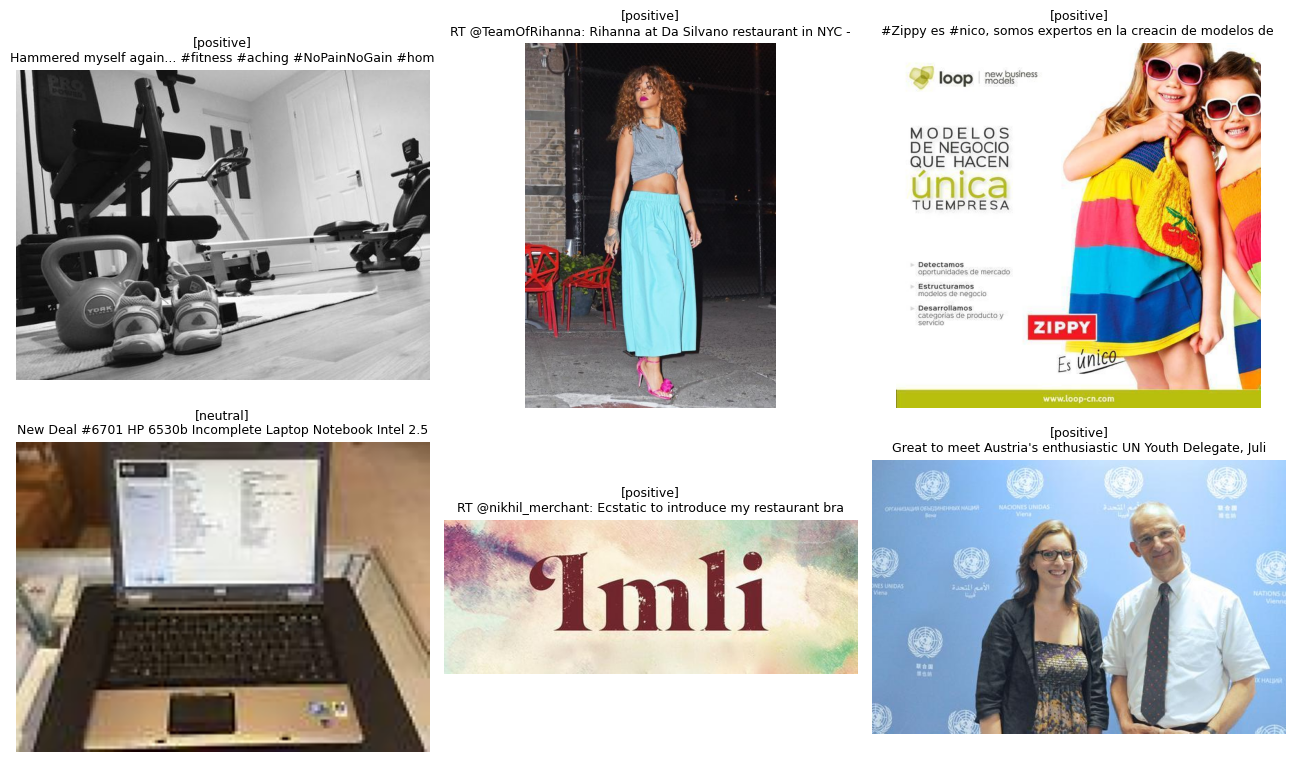

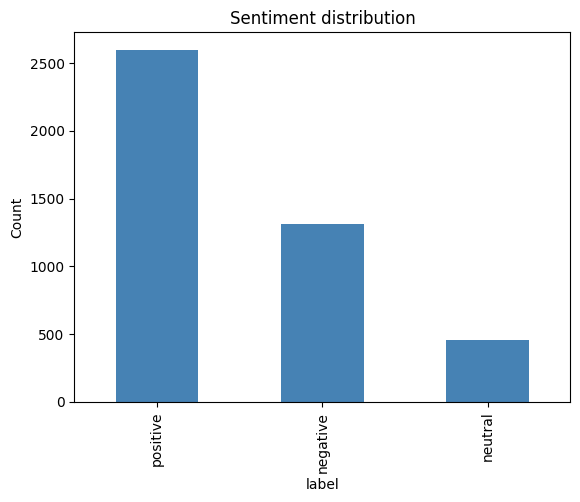

In [ ]:
# CELL 5: Display a few tweets with their images to show the multimodal data

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (_, r) in zip(axes.ravel(), df.sample(6, random_state=1).iterrows()):
    ax.imshow(Image.open(r['image']).convert('RGB'))
    ax.set_title(f"[{r['label']}]\n" + r['text'][:60], fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

df['label'].value_counts().plot(kind='bar', color='steelblue', title='Sentiment distribution')
plt.ylabel('Count'); plt.show()

Cell 6: Label encoding and train/test split

In [ ]:
# CELL 6: Encode labels and split into training and test sets

le = LabelEncoder()
y = le.fit_transform(df['label'])
print(dict(zip(le.classes_, range(len(le.classes_)))))

# 80% train / 20% test, stratified so every sentiment keeps its proportion
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=42)
y_train, y_test = y[idx_train], y[idx_test]

# Baseline: always predicting the biggest class (any model should beat this)
majority = np.bincount(y_train).argmax()
print("Majority-class baseline accuracy:", round(accuracy_score(y_test, [majority] * len(y_test)), 3))

{'negative': 0, 'neutral': 1, 'positive': 2}
Majority-class baseline accuracy: 0.596


Cell 7: Text features

In [28]:
# CELL 7: Extract text features (VADER sentiment on raw text + TF-IDF on cleaned text)
from sklearn.feature_extraction.text import TfidfVectorizer

analyzer = SentimentIntensityAnalyzer()
def sentiment_feats(text):
    s = analyzer.polarity_scores(str(text))        # VADER works best on the raw text
    return [s['neg'], s['neu'], s['pos'], s['compound']]

X_sent = np.array([sentiment_feats(t) for t in df['text']])

# TF-IDF: converts each cleaned tweet into numbers based on how important its words are
vectorizer = TfidfVectorizer(max_features=3000, stop_words="english", ngram_range=(1, 2), min_df=2)
vectorizer.fit(df["clean_text"].iloc[idx_train])   # learn the vocabulary from training text only
X_tfidf = vectorizer.transform(df["clean_text"]).toarray()

# Final text features = sentiment scores + TF-IDF values
X_text = np.hstack([X_sent, X_tfidf])
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print("Text feature shape:", X_text.shape)         # (N, 3004)

Vocabulary size: 3000
Text feature shape: (4364, 3004)


Cell 8: Image features

In [ ]:
# CELL 8: Extract image features using a pretrained ResNet50 (trained on ImageNet)

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
resnet.fc = torch.nn.Identity()                        # remove the final classifier, keep the 2048-number feature vector
resnet = resnet.to(device).eval()

# Resize and normalise every image the way ResNet expects
img_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def load_img(path):
    try:
        return img_tf(Image.open(path).convert('RGB'))
    except Exception:
        return torch.zeros(3, 224, 224)                # corrupt image -> blank placeholder

def image_features(paths, bs=64):
    feats = []
    for s in range(0, len(paths), bs):
        batch = torch.stack([load_img(p) for p in paths[s:s + bs]]).to(device)
        with torch.no_grad():
            feats.append(resnet(batch).cpu().numpy())
    return np.vstack(feats)

X_img = image_features(df['image'].tolist())
print("Image feature shape:", X_img.shape)             # (N, 2048)

Image feature shape: (4364, 2048)


Cell 9: Fusion

In [34]:
# CELL 9: Scale image features and combine text + image features (early fusion)

scaler = StandardScaler()
scaler.fit(X_img[idx_train])                           # fit on training data only (no leakage)
X_img_s = scaler.transform(X_img)

X_fused = np.hstack([X_text, X_img_s])                 # text and image features side by side
print("Fused feature shape:", X_fused.shape)           # (N, 2436)

Fused feature shape: (4364, 5052)


Cell 10: Train sentiment models and compare

In [29]:
# CELL 10: Train Logistic Regression on text only, image only, early fusion and late fusion

def fit_lr(X, C):
    m = LogisticRegression(max_iter=3000, class_weight='balanced', C=C)
    return m.fit(X[idx_train], y_train)

m_text = fit_lr(X_text,  C=1.0)
m_img  = fit_lr(X_img_s, C=0.01)

# Choose C for early fusion using a validation split taken from the TRAINING data only
tr, va = train_test_split(idx_train, test_size=0.2, stratify=y[idx_train], random_state=0)
best_C, best_f1 = None, -1
for C in [0.01, 0.05, 0.1, 0.5, 1.0]:
    m = LogisticRegression(max_iter=3000, class_weight='balanced', C=C).fit(X_fused[tr], y[tr])
    f1 = f1_score(y[va], m.predict(X_fused[va]), average='macro')
    print(f"early fusion C={C}: validation macro F1 {f1:.3f}")
    if f1 > best_f1: best_C, best_f1 = C, f1
print("Chosen C for early fusion:", best_C, "\n")
m_early = fit_lr(X_fused, C=best_C)

p_text  = m_text.predict_proba(X_text[idx_test])
p_img   = m_img.predict_proba(X_img_s[idx_test])
p_early = m_early.predict_proba(X_fused[idx_test])
p_late  = 0.5 * p_text + 0.5 * p_img               # late fusion: average the two models' probabilities

results = {}
for name, p in [('Text only', p_text), ('Image only', p_img),
                ('Early fusion', p_early), ('Late fusion', p_late)]:
    pr = p.argmax(1)
    results[name] = (accuracy_score(y_test, pr), f1_score(y_test, pr, average='macro'))
    print(f"{name:13s} accuracy: {results[name][0]:.3f} | macro F1: {results[name][1]:.3f}")

early fusion C=0.01: validation macro F1 0.547
early fusion C=0.05: validation macro F1 0.532
early fusion C=0.1: validation macro F1 0.526
early fusion C=0.5: validation macro F1 0.516
early fusion C=1.0: validation macro F1 0.515
Chosen C for early fusion: 0.01 

Text only     accuracy: 0.629 | macro F1: 0.546
Image only    accuracy: 0.608 | macro F1: 0.534
Early fusion  accuracy: 0.643 | macro F1: 0.563
Late fusion   accuracy: 0.692 | macro F1: 0.605


Cell 11: Results and graphs

              precision    recall  f1-score   support

    negative       0.60      0.64      0.62       262
     neutral       0.38      0.44      0.41        91
    positive       0.81      0.76      0.79       520

    accuracy                           0.69       873
   macro avg       0.60      0.61      0.60       873
weighted avg       0.70      0.69      0.70       873



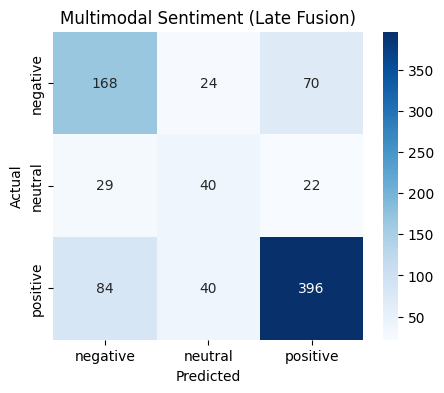

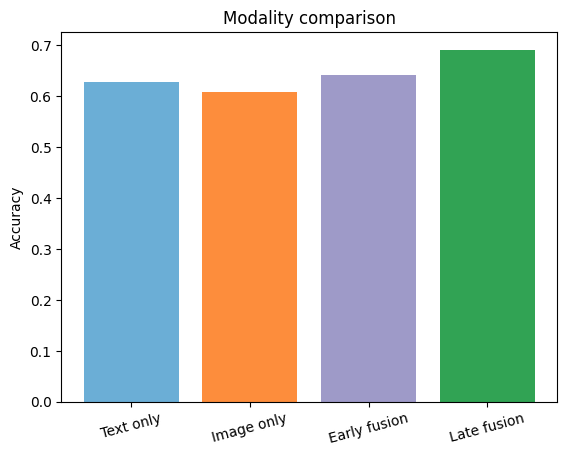

In [32]:
# CELL 11: Evaluate the best fused model and visualise the results

pred_late = p_late.argmax(1)
print(classification_report(y_test, pred_late, target_names=le.classes_))

# Confusion matrix: shows which sentiments get confused with each other
cm = confusion_matrix(y_test, pred_late)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Multimodal Sentiment (Late Fusion)')
plt.show()

# Bar chart comparing all approaches
names = list(results.keys())
plt.bar(names, [results[n][0] for n in names], color=['#6baed6', '#fd8d3c', '#9e9ac8', '#31a354'])
plt.ylabel('Accuracy'); plt.title('Modality comparison'); plt.xticks(rotation=15); plt.show()

Cell 12: Sample Input / Sample Output

SAMPLE INPUT
Text: #shoes Brand New Reebok Walking Tennis Walk Euphoric Sport White Medium Shoes 10.5


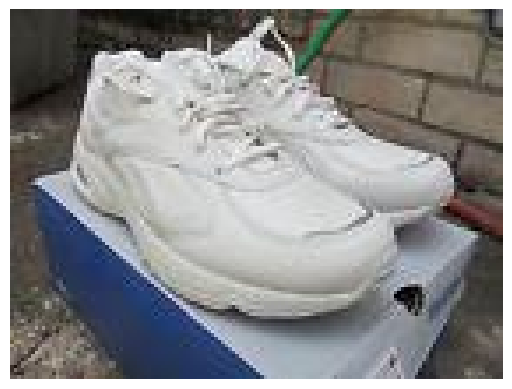

SAMPLE OUTPUT
Text Features Shape : (3004,)
Image Features Shape: (2048,)
Combined Features Shape: (5052,)
Actual Sentiment   : neutral
Predicted Sentiment: neutral


In [31]:
# CELL 12: Show one sample input and the model's output

def predict_sentiment(text, img_path):
    # Text features: VADER on raw text + TF-IDF on cleaned text
    t = np.hstack([sentiment_feats(text), vectorizer.transform([preprocess_text(str(text))]).toarray()[0]])
    im = scaler.transform(image_features([img_path]))[0]
    p = 0.5 * m_text.predict_proba([t]) + 0.5 * m_img.predict_proba([im])   # late fusion
    return le.classes_[p.argmax()], t.shape, im.shape

k = idx_test[0]
pred_label, t_shape, i_shape = predict_sentiment(df['text'][k], df['image'][k])

print("SAMPLE INPUT")
print("Text:", df['text'][k])
plt.imshow(Image.open(df['image'][k]).convert('RGB')); plt.axis('off'); plt.show()

print("SAMPLE OUTPUT")
print("Text Features Shape :", t_shape)
print("Image Features Shape:", i_shape)
print("Combined Features Shape:", (t_shape[0] + i_shape[0],))
print("Actual Sentiment   :", df['label'][k])
print("Predicted Sentiment:", pred_label)

Wrong predictions: 269 out of 873 test samples

----------------------------------------
Text     : RT @SherwoodRangerT: Many days lacking of tree of the day sorry here's today's! @AncientTreesATF two in one!


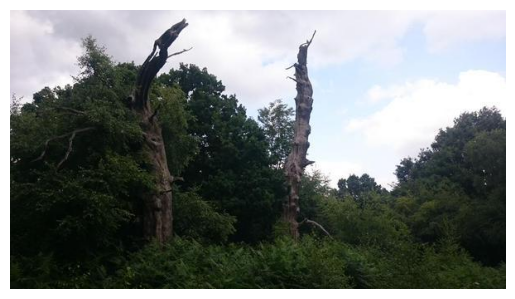

Actual   : negative
Predicted: positive

----------------------------------------
Text     : Ready for my first full week of training w/the premier team! #Ecstatic #CarpeDiem


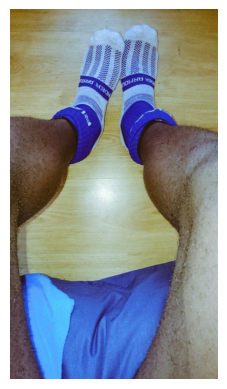

Actual   : negative
Predicted: positive

----------------------------------------
Text     : RT @thedailybeast: Nine people in Florida have been diagnosed with leprosy (yes, leprosy). The source? Armadillos http://t.co/HKkj4YW4sm ht


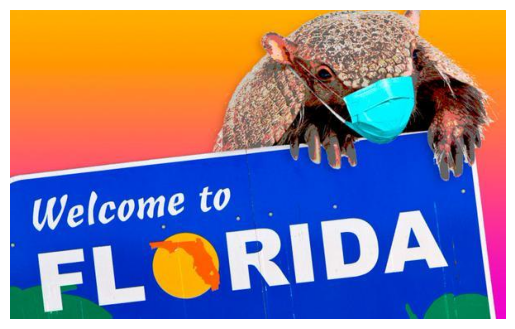

Actual   : negative
Predicted: positive


In [33]:
# CELL 13: Show test samples where the model's prediction is WRONG (error analysis)

# Find test samples where the late-fusion prediction differs from the actual label
wrong = [k for k, p in zip(idx_test, p_late.argmax(1)) if le.classes_[p] != df['label'][k]]
print(f"Wrong predictions: {len(wrong)} out of {len(idx_test)} test samples")

# Show the first 3 wrong samples with their image
for k in wrong[:3]:
    pred_label, _, _ = predict_sentiment(df['text'][k], df['image'][k])
    print("\n" + "-" * 40)
    print("Text     :", df['text'][k])
    plt.imshow(Image.open(df['image'][k]).convert('RGB')); plt.axis('off'); plt.show()
    print("Actual   :", df['label'][k])
    print("Predicted:", pred_label)